In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, SplineTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.base import clone

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
auto = pd.read_csv("../../data/Auto.csv", na_values="?").dropna().reset_index(drop=True)
len(auto)

392

In [3]:
auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino


# 1.1a)

In [7]:
auto['cylinders'].value_counts()

cylinders
4    199
8    103
6     83
3      4
5      3
Name: count, dtype: int64

Text(0.5, 1.0, 'MPG by # of Cylinders')

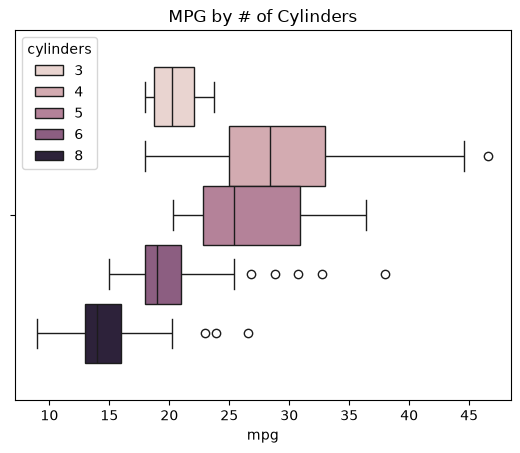

In [14]:
sns.boxplot(data=auto, x='mpg', hue='cylinders')
plt.title('MPG by # of Cylinders')

# 1.1b & c)

Text(0.5, 1.0, 'MPG by cylinder group')

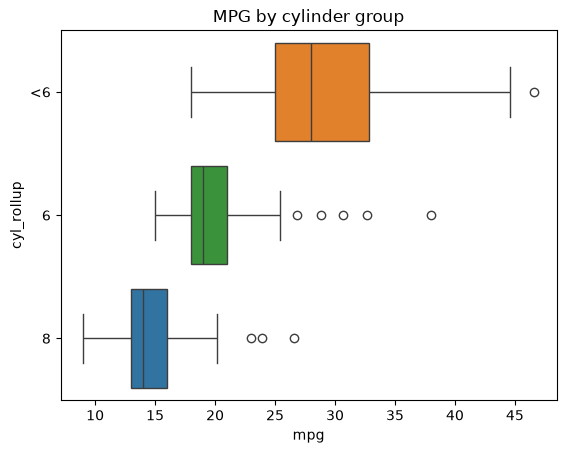

In [ ]:
bools = [auto["cylinders"] < 6, auto["cylinders"] == 6, auto["cylinders"] == 8,]
labels = ["<6", "6", "8"]

auto["cyl_rollup"] = np.select(bools, labels, default="other")

sns.boxplot(data=auto, x='mpg', y='cyl_rollup',hue='cyl_rollup', order=labels)
plt.title("MPG by cylinder group")

6 and 8 cylinders remain the same from the first plot, and <6 combines 3, 4, and 5 into one boxplot. The only outlier that existed in the first plot (4 cylinders) for this bucket is still classified as an outlier after being combined with the other two classifications.

# 1.1d)

We should exclude name from the dataset because it is very specific, and would likely not give us any predictive power once properly encoded with dummies or OneHot. At the very most, I'd split the string and keep the make of the car (looks like the first word in name) to see if the manufacturer has any predictive power on mpg or other variables. 

# 1.2a)

In [40]:
num_cols = ["displacement", "horsepower", "weight", "acceleration", "year"]
X = auto[num_cols]
y = auto["mpg"]

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=num_cols)

kf = KFold(n_splits=5, shuffle=True, random_state=6021)

for k in range(1, 5):
    sfs = SequentialFeatureSelector(LinearRegression(), n_features_to_select=k, direction="forward",
        cv=kf,)
    sfs.fit(X_scaled, y)
    print(k, list(sfs.get_feature_names_out()))

1 ['weight']
2 ['weight', 'year']
3 ['displacement', 'weight', 'year']
4 ['displacement', 'weight', 'acceleration', 'year']


# 1.2b)

In [28]:
sfs_back = SequentialFeatureSelector(
    LinearRegression(), n_features_to_select=3, direction="backward", cv=kf
).fit(X_scaled, y)
print(list(sfs_back.get_feature_names_out()))

['displacement', 'weight', 'year']


Yes, forward and backward selection both choose ['displacement', 'weight', 'year']. This doesn't guarantee that it found the best model since they can only move one step at a time and evaluate that given model, it doesn't test all combinations of parameters. 

# 1.1.c)

In [ ]:
trio = auto[["displacement", "horsepower", "weight"]]
trio.corr().round(2)

X_vif = sm.add_constant(trio)
vif = pd.DataFrame({"feature": X_vif.columns, "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],})
vif

,feature,VIF
0,const,31.164849
1,displacement,10.310539
2,horsepower,5.287295
3,weight,7.957383


For backward selection, some important columns with a high VIF may be deleted prematurely since it shares its variance with another predictor. Additionally removing one collinear variable may make the other one a worse predictor, leading to an overall worse model. For forward selection, it may block out a variable's collinear counterpart when it may be a better predictor in combination with other variables. 

# 2.1a)

In [33]:
num_feats = ["displacement", "weight", "year"]
cat_feats = ["cyl_rollup", "origin"]

prep_A = ColumnTransformer([
    ("num", StandardScaler(), num_feats),
])
prep_B = ColumnTransformer([
    ("num", StandardScaler(), num_feats),
    ("cat", OneHotEncoder(drop="first"), cat_feats),
])

model_A = Pipeline([("prep", prep_A), ("lr", LinearRegression())])
model_B = Pipeline([("prep", prep_B), ("lr", LinearRegression())])

X = auto[num_feats + cat_feats]
y = auto["mpg"]
models = {"Model A": model_A, "Model B": model_B}

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=6021)

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({
        "model": name,
        "train_RMSE": mean_squared_error(y_train, model.predict(X_train)),
        "test_RMSE":  mean_squared_error(y_test,  model.predict(X_test)),
    })

split_table = pd.DataFrame(rows).round(3)
split_table

,model,train_RMSE,test_RMSE
0,Model A,10.713,15.439
1,Model B,9.360,13.411


# 2.1b) 

Model b is performing better (lower RMSE) on both the training and testing data, so I would choose it over a. 

# 2.2 a b and c)

In [38]:
cv_rows = []
for name, model in models.items():
    for k in [5, 10]:
        kf = KFold(n_splits=k, shuffle=True, random_state=6021)
        scores = cross_val_score(model, X, y, cv=kf, scoring="neg_root_mean_squared_error")
        cv_rows.append({"model": name, "k": k, "cv_RMSE": -scores.mean()})

cv_table = pd.DataFrame(cv_rows).pivot(index="model", columns="k", values="cv_RMSE")
cv_table.round(3)

k,5,10
model,,
Model A,3.425,3.375
Model B,3.235,3.206


The RMSE for the k-fold validation models is much lower than the previous models trained on the 80/20 split, roughly about 1/4 than the test RMSE. There isn't too much of a difference in RMSE between 5 and 10 folds so it might be more computationally efficient to stick with 5 folds. Model B is still outperforming model A so my choice is still B.

# 2.3a)

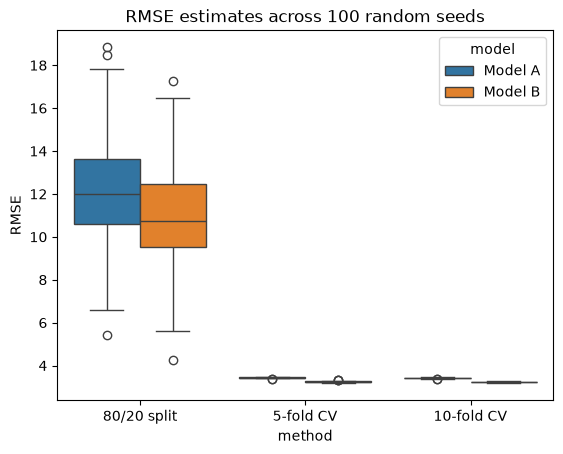

mean    std
model   method                    
Model A 10-fold CV    3.418  0.017
        5-fold CV     3.440  0.018
        80/20 split  12.171  2.382
Model B 10-fold CV    3.225  0.022
        5-fold CV     3.252  0.027
        80/20 split  10.961  2.276

In [63]:
# ai used to help build the loop structure
X = auto[num_feats + cat_feats]   # rebuild: Part 3 overwrote X with bike data
y = auto["mpg"]
results = []
for seed in range(100):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    for name, model in models.items():
        m = clone(model).fit(X_tr, y_tr)
        results.append({"seed": seed, "model": name, "method": "80/20 split",
                        "RMSE": mean_squared_error(y_te, m.predict(X_te))})
        for k in [5, 10]:
            kf = KFold(n_splits=k, shuffle=True, random_state=seed)
            s = cross_val_score(model, X, y, cv=kf, scoring="neg_root_mean_squared_error")
            results.append({"seed": seed, "model": name, "method": f"{k}-fold CV",
                            "RMSE": -s.mean()})

res = pd.DataFrame(results)   # 100 seeds × 2 models × 3 methods = 600 rows

sns.boxplot(data=res, x="method", y="RMSE", hue="model")
plt.title("RMSE estimates across 100 random seeds")
plt.show()

res.groupby(["model", "method"])["RMSE"].agg(["mean", "std"]).round(3)

I would choose model b again, it consistently has a lower RMSE than A for the 80/20 split and both k folds.

# 2.3b)

Possibly? The added categorical variables make model b a slightly better predictor, but it's also more complicated and the difference in RMSE isn't that meaningful. As long as model b isn't too computationally expensive, I would choose that otherwise model a isn't that much worse of a predictor.

# 3.1a b & c)

In [42]:
bike = pd.read_csv("../../data/bike-sharing-daily.csv")
X = bike[["temp"]]
y = bike["cnt"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=6021)

bike_models = {
    "A: Linear": make_pipeline(LinearRegression()),
    "B: Poly d=9": make_pipeline(StandardScaler(), PolynomialFeatures(9, include_bias=False),
                                  LinearRegression()),
    "C: Spline k=7": make_pipeline(SplineTransformer(degree=3, n_knots=7, knots="quantile"),
                                    LinearRegression()),
}

for m in bike_models.values():
    m.fit(X_train, y_train)

# 3.1d)

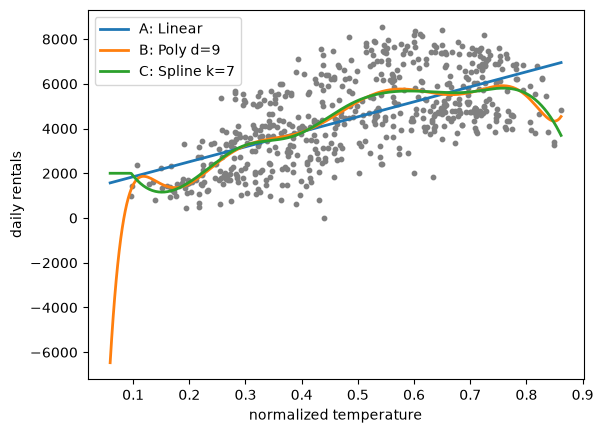

In [46]:
grid = pd.DataFrame({"temp": np.linspace(X["temp"].min(), X["temp"].max(), 300)})

plt.scatter(X_train["temp"], y_train, s=10, color="gray")
for name, m in bike_models.items():
    plt.plot(grid["temp"], m.predict(grid), linewidth=2, label=name)
plt.xlabel("normalized temperature") 
plt.ylabel("daily rentals")
plt.legend()

The linear model fits fairly well, and the spline and polynomial models nearly mirror each other away from the edges of the data. As mentioned in class the spline model is flat at its ends and the polynomial veers off quickly, so both of those models would not be good at predicting any data near or past the range of the data.

# 3.2 - 3.3)

In [49]:
kf5 = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, m in bike_models.items():
    cv = cross_val_score(m, X_train, y_train, cv=kf5, scoring="neg_root_mean_squared_error")
    rows.append({
        "model": name,
        "train_RMSE": mean_squared_error(y_train, m.predict(X_train)),
        "test_RMSE":  mean_squared_error(y_test,  m.predict(X_test)),
        "cv5_RMSE":   -cv.mean(),
    })
pd.DataFrame(rows).round(1)

,model,train_RMSE,test_RMSE,cv5_RMSE
0,A: Linear,2229921.6,2440318.7,1494.6
1,B: Poly d=9,1942878.8,2512790.1,1404.4
2,C: Spline k=7,1948856.2,2146956.6,1405.4


- 3.2a) The polynomial model has the best training RMSE and the spline model has teh best test RMSE
- 3.2b) No, the linear and spline models have a very similar train and test RMSE but the polynomial model's test RMSE grows a considerable amount more than the the other two
- 3.2c) I would consider the polynomial and spline model to be overfit. Looking at the data, it is at most appropriately fit by a second order polynomial. 7 knots and 9 degrees is just overkill and introduces variance in its predictions. I guess with that argument the linear model is a little underfit, but it still fits the data fairly well
- 3.3) It definitely gives me more confidence saying that the spline and polynomial models are overfit. Adding more degrees of power will always decrease RMSE, but that increases variance and doesn't mean that those models are automatically better

# 4.1) 

,mean,std
model,,
A: Linear,5197.5,76.1
B: Poly d=9,5720.0,144.6
C: Spline k=7,5669.0,178.9


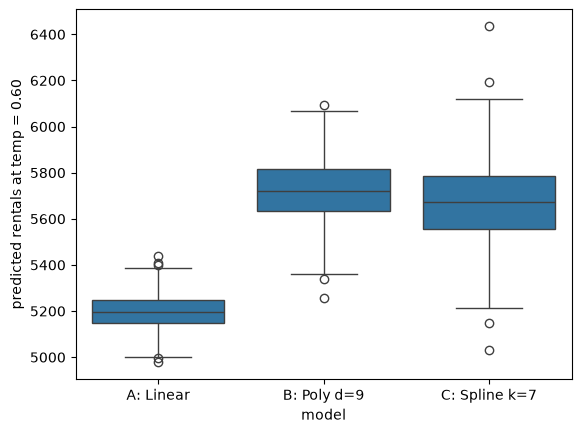

In [ ]:
rng = np.random.default_rng(6021)
B = 500
n = len(X_train)
x0 = pd.DataFrame({"temp": [0.60]})

boot = []
for name, model in bike_models.items():
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        Xb, yb = X_train.iloc[idx], y_train.iloc[idx]
        m = clone(model).fit(Xb, yb)
        boot.append({"model": name, "pred": m.predict(x0)[0]})

boot = pd.DataFrame(boot)

sns.boxplot(data=boot, x="model", y="pred")
plt.ylabel("predicted rentals at temp = 0.60")

boot.groupby("model")["pred"].agg(["mean", "std"]).round(1)

- a) The linear model appears to be the most stable while the spline model is the most variable. 
- b) The linear model is much less variable comparted to the polynomial and spline models, which leads me to believe that increasing model flexibility overfits the training data, which leads to greater variance in its predictions
- c) Considering the temp variable's variance among riders grows as temperature rises (as shown below), I would expect more variance among predictions at temp=0.60. I don't think this says as much about the model's variance as it does the data's, but it therefore doesn't generalize as well as the variance continues to grow with temp.

<Axes: xlabel='temp', ylabel='cnt'>

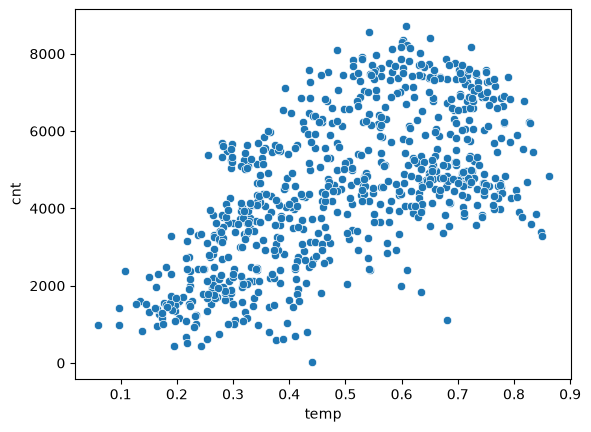

In [57]:
sns.scatterplot(data=bike, x='temp', y='cnt')

# 4.2)

- a) Linear: The linear model is less flexible compared to the other two and slightly underfits the data. Therefore its predictions will be more biased, but much more consistent and has better generalization; Polynomial: The polynomial model has more flexibility due to its high-power polynomial, and it delivers the best training RMSE. But looking at the last boxplot, its predictions are more variable and that's shown in the test RMSE where it performs worse than the linear model; Spline: The spline model suffers from the same things as the polynomial model - overfitting, good training RMSE, poor test RMSE, and variable predictions. 
- b) Choosing the model with the smallest training RMSE is incorrect reasoning for a few reasons. Assuming it was on all of the data available with no holdout set, the model could be overfit and perform poorly with predictions on unseen data, making it less generalizable. It may be less biased, but the predictions will be more variable